# PROBLEMA 1: Regressão Linear para Previsão de Produção de Energia em uma Usina de Ciclo Combinado

Nesse projeto, eu devo **construir um modelo matemático de regressão linear múltipla** para prever a produção de energia baseando-se em sensores ambientais, permitindo a otimização do despacho energético.

# Coisas que devo fazer com o Dataset 

1. Calcule a correlação entre as variáveis independentes (AT, V, AP, RH) e a variável dependente (PE). Quais variáveis parecem ter maior influência na produção de energia ?

2. Calcule a correlação entre as variáveis independentes (AT, V, AP, RH) entre si. Existe alguma relação forte entre elas? Se sim, isso pode indicar multicolinearidade.

3. Construa um modelo de regressão linear múltipla utilizando as variáveis independentes (AT, V, AP, RH) para prever a variável dependente (PE). Divida os dados em treino (80%) e teste (20%).

4. Avalie o desempenho do modelo utilizando métricas como R², RMSE e MAE. O modelo é adequado para prever a produção de energia? Justifique sua resposta.

**OBS** Para esse problema é preciso realizar:

- pré-processamento dos dados (incluindo a normalização ou padronização das variáveis independentes)

- tratamento de valores ausentes

- divisão dos dados em conjuntos de treino e teste

In [42]:
# importando algumas bibliotecas importantes 
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [43]:
# importando o dataset
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
combined_cycle_power_plant = fetch_ucirepo(id=294) 
  
# data (as pandas dataframes) 
X = combined_cycle_power_plant.data.features 
y = combined_cycle_power_plant.data.targets 
  
# juntando as colunas de features + target
df = pd.concat([X,y], axis=1)

# verificando a quantidade de amostras
df.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      9568 non-null   float64
 1   V       9568 non-null   float64
 2   AP      9568 non-null   float64
 3   RH      9568 non-null   float64
 4   PE      9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB


In [45]:
# verificando a existência de dados faltantes
df.isna().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [46]:
# verificando por meio do boxplot, como estão as escalas de cada uma das features 
X.boxplot(column= ['AT','V','AP','RH'])

<Axes: >

Como é possível ver, nem todos os dados estão em uma mesma escala... **O conjunto de dados será splitado e depois os dados serão normalizados** e isso será feito para evitar data leakage

In [47]:
# splitando os dados
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state= 42, test_size= 0.2)

print('Quantidade de amostras de treino: ', X_train.shape[0])
print('Quantidade de amostras de teste:', X_test.shape[0])

Quantidade de amostras de treino:  7654
Quantidade de amostras de teste: 1914


In [48]:
# normalizando as escalas dos dados
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train) 
X_test_scaled = scaler.transform(X_test) # usando a normalização já feita anteriormente do conjunto de treino

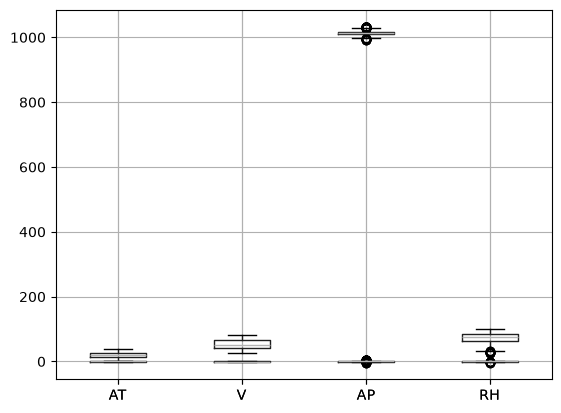

In [49]:
# verificando se a normalização ocorreu, fazendo novamente um boxplot
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)

X_train_scaled_df.boxplot(column= ['AT','V','AP','RH'])
plt.show()

## 1. Calcule a correlação entre as variáveis independentes (AT, V, AP, RH) e a variável dependente (PE). Quais variáveis parecem ter maior influência na produção de energia ?

As variáveis independentes (AT, V, AP, RH) representam as features que serão utilizadas como entrada do modelo de regressão linear que será aplicado. Além disso, a variável dependente (PE) representa a coluna TARGET, esta que será responsável por guardar os rótulos de cada uma das amostras. 

Nesse sentido, é possível analisar inicialmente qual será a feature que poderá causar um impacto maior no aprendizado do modelo (e, consequentemente, na inferência do mesmo) analisando a correlação entre cada uma das features com a variável target. O objetivo da correlação será indicar o quão forte é a relação de linearidade entre uma das features e a variável target (correlação de pearson).

---

1. Primeiramente, calculei todas as correlações de pearson de todas as features com a variável target e depois ordenei por magnitude para saber qual é a feature de maior influência
2. Plotei o gráfico de cada uma delas

In [50]:
correlacoes_pe = df.corr()['PE'].drop('PE')

print("Correlações com a variável target PE:")
print(correlacoes_pe)

Correlações com a variável target PE:
AT   -0.948128
V    -0.869780
AP    0.518429
RH    0.389794
Name: PE, dtype: float64


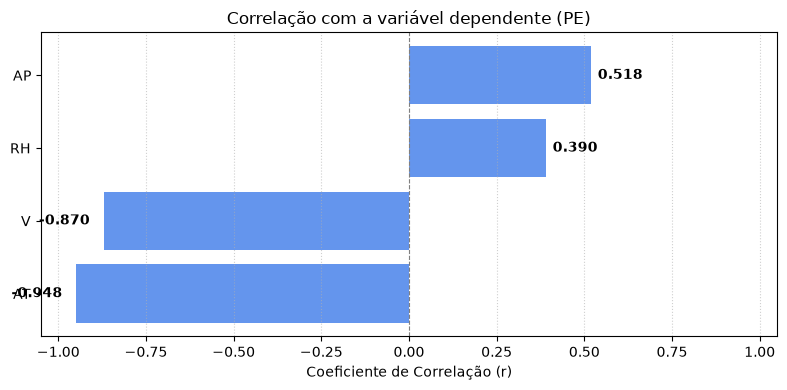

In [51]:
# ordenando os valores pro gráfico 
correlacoes_ordenadas = correlacoes_pe.sort_values()
plt.figure(figsize=(8, 4))
bars = plt.barh(correlacoes_ordenadas.index, correlacoes_ordenadas.values, color='cornflowerblue')

# adicionando linha de referência no 0 e rótulos
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.title('Correlação com a variável dependente (PE)', fontsize=12)
plt.xlabel('Coeficiente de Correlação (r)', fontsize=10)
plt.xlim(-1.05, 1.05)

# exibindo os valores para cada bar
for bar in bars:
    width = bar.get_width()
    ha = 'right' if width < 0 else 'left'
    offset = -0.04 if width < 0 else 0.02
    plt.text(width + offset, bar.get_y() + bar.get_height()/2, f'{width:.3f}', 
             va='center', ha=ha, fontsize=10, fontweight='bold')
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

É possível concluir que a feature de temperatura ambiente `AT` que possui maior correlação com a variável target `PE`, com -0,948 (-94,80%). Vale mencionar que além da correlação de ter indicado que a relação de linearidade entre `AT` e `PE` é a mais forte dentre as demais features, o sinal negativo indica que `AT` e `PE` são inversamente proporcionais. Ou seja, **quanto menor for a temperatura ambiente (AT), maior será `PE`**.

## 2. Calcule a correlação entre as variáveis independentes (AT, V, AP, RH) entre si. Existe alguma relação forte entre elas? Se sim, isso pode indicar multicolinearidade.

Para calcular a correlação entre cada uma das features, será plotada uma matriz de correlação composta apenas das features. O objetivo dela será detectar quais são as combinações específicas que possuem maior correlação entre si.

In [52]:
# matriz de correlação
corr_X = X.corr()
print("Matriz de Correlação entre as Variáveis Independentes:")
display(corr_X)

Matriz de Correlação entre as Variáveis Independentes:


,AT,V,AP,RH
AT,1.000000,0.844107,-0.507549,-0.542535
V,0.844107,1.000000,-0.413502,-0.312187
AP,-0.507549,-0.413502,1.000000,0.099574
RH,-0.542535,-0.312187,0.099574,1.000000


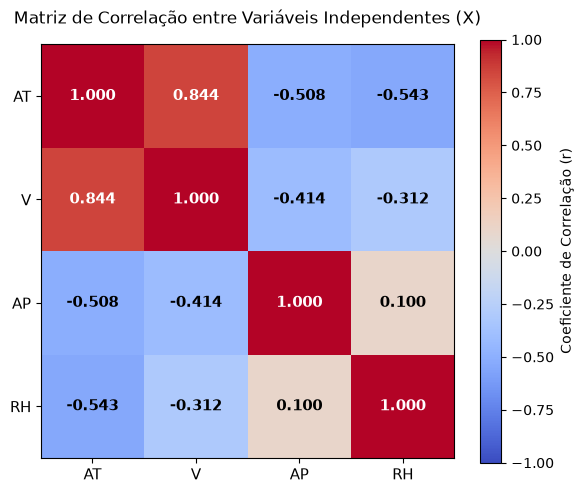

In [53]:
# matriz de correlação (Heatmap)
fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.imshow(corr_X, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(cax, label='Coeficiente de Correlação (r)')

# config dos rótulos nos eixos
features = corr_X.columns
ax.set_xticks(range(len(features)))
ax.set_yticks(range(len(features)))
ax.set_xticklabels(features, fontsize=11)
ax.set_yticklabels(features, fontsize=11)

# passando os valores numéricos para cada célula (para cada linha i de cada coluna j)
for i in range(len(features)):
    for j in range(len(features)):
        val = corr_X.iloc[i, j]
        color = 'white' if abs(val) > 0.6 else 'black'
        ax.text(j, i, f'{val:.3f}', ha='center', va='center', 
                color=color, fontsize=11, fontweight='bold')

plt.title('Matriz de Correlação entre Variáveis Independentes (X)', fontsize=12, pad=15)
plt.tight_layout()
plt.show()

Ao analisar a matriz de correlação, podemos observar que existem dois pontos que devem ser salientados:

1. **As features `V` e `AT` possuem um nível muito alto de correlação**, o que pode indicar facilmente multicolinearidade. Ou seja, ambas as features carregam uma parte significativa de uma mesma informação.

2. As features de `AP` e `RH` possuem um nível muito baixo de correlação. Isso indica que as informações que essas features carregam são quase distintas, ou seja, são features insubstituíveis para esse cenário.

## 3. Construa um modelo de regressão linear múltipla utilizando as variáveis independentes (AT, V, AP, RH) para prever a variável dependente (PE). Divida os dados em treino (80%) e teste (20%).

Já tinha feito o split dos dados anteriormente, agora irei treinar o modelo de regressão linear utilizando 80% do conjunto de dados e realizar o teste do modelo com os outros 20%.

In [54]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 4)","[[-14.76, -2.95, 0.37, -2.31]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[454.43]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4,)","[136.66, 83.33, 64.89, 28.05]"


## 4. Avalie o desempenho do modelo utilizando métricas como R², RMSE e MAE. O modelo é adequado para prever a produção de energia? Justifique sua resposta.

Importei as métricas do sklearn, executei elas e fiz as avaliações depois disso

In [ ]:
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
from sklearn.metrics import mean_squared_error

# fazendo as predições do modelo 
y_pred = model.predict(X_test_scaled)

# extraindo as métricas
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("R² = ", r2)
print("RMSE = ", rmse)
print("MAE = ", mae)

R² =  0.9301046431962188
RMSE =  4.502633229532186
MAE² =  3.595913178273408


Ao final, é possível concluir que o modelo é sim adequado para prever a produção de energia.

1. O coeficiente R² (de determinação) foi consideravelmente alto (~ 93 %)

O coeficiente R² é a medida estatística que indica a proporção de variabilidade da variável dependente (target) que é explicada pelas variáveis independentes no modelo de regressão que, nesse caso, apresentou bons resultados.

Em outras palavras, **o modelo consegue explicar 93,01% de toda a variação da geração de energia usando apenas o modelo de regressão linear proposto com as 4 features**. No cenário onde a medição dos valores extraídos dos sensores carregam ruído inerente, explicar bem essa variação por si só já se torna um bom indício de que o modelo é adequado para esse projeto.

2. O MAE indica que o erro é muito baixo

O erro médio absoluto registrou um valor de ~ 3.6. Ou seja, em média, **o MAE diz que a previsão do modelo erra numa amplitude de 3.59 MW**. Segundo a EIA - U.S Energy Information Administration, *a média de potência ou capacidade de geração de uma Usina de Ciclo Combinado (CCGT) varia geralmente entre 400 MW e 800 MW por bloco de energia padrão*.

Ou seja, **pegando um cenário onde é gerado 400 MW, o erro médio absoluto representa menos de 1%**.

3. O RMSE indica a existência de poucos erros grosseiros

A raíz do erro médio quadrático é uma métrica que eleva os erros ao quadrado, ou seja, é uma métrica mais sensível aos erros e, para esse projeto, é apenas ligeiramente maior do que a MAE. Caso houvesse precivisões com erros significativos, o RMSE seria significativamente maior do que o MAE. Entre outras palavras, o modelo além de errar pouco, ele é consistente mesmo nos erros.
